In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
import sys
import os

# ==========================================
# 1. 配置与加载
# ==========================================
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

# 变量映射 (基于你确认过的真实列名)
col_map = {
    'albedo': 'Albedo',             # 目标
    'strd': 'Strd',                 # 长波辐射
    'ssrd': 'Ssrd',                 # 短波辐射
    't2m': 'T2m',                   # 2m气温
    'u10': 'U10',                   # 纬向风 (西风分量)
    'v10': 'V10',                   # 经向风 (南风分量)
    'altitude_last_valid': 'Alt',   # 海拔
    'longitude': 'Lon'              # 经度
}

print(f"正在读取文件: {file_path} ...")
if not os.path.exists(file_path):
    print("❌ 文件不存在")
    sys.exit(1)

try:
    df = pd.read_csv(file_path, usecols=list(col_map.keys()))
    df.rename(columns=col_map, inplace=True)
    df.dropna(inplace=True)
    print(f"数据加载成功。有效样本数: {len(df):,}")
except Exception as e:
    print(f"❌ 读取错误: {e}")
    sys.exit(1)

# 定义要分析的物理变量列表
phys_vars = ['Strd', 'Ssrd', 'T2m', 'U10', 'V10']

# ==========================================
# 第一步：海拔分组分析 (Inland vs Margin)
# ==========================================
print("\n" + "="*80)
print("📊 STEP 1: 海拔分组分析 (Elevation Regimes)")
print("   对比内陆 (>1500m) 与 边缘 (<1500m) 的整体机制")
print("="*80)

regions = {
    'Inland (>1500m)': df[df['Alt'] > 1500],
    'Margin (<1500m)': df[df['Alt'] <= 1500]
}

for name, subset in regions.items():
    print(f"\n📍 [{name}] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10} | {'Interpretation Hint'}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        
        # 简单的自动解读标记
        hint = ""
        if "Margin" in name and var == "Strd" and r < -0.3: hint = "🔥 Melt driven (Cloud/Warmth)"
        if "Margin" in name and var == "Ssrd" and r < -0.3: hint = "☀️ Melt driven (Sun)"
        if "Inland" in name and var == "Strd" and r < 0:    hint = "❄️ Radiative Cooling?"
        
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}  | {hint}")

# ==========================================
# 第二步：内陆东西细分 (Inland West vs East)
# ==========================================
print("\n" + "="*80)
print("🧭 STEP 2: 内陆东西部细分 (Inland West vs East)")
print("   仅分析海拔 > 1500m 区域，以 -42°W 为界")
print("="*80)

# 只取内陆
df_inland = df[df['Alt'] > 1500].copy()
# 划分东西
df_inland['Sector'] = df_inland['Lon'].apply(lambda x: 'West' if x < -42 else 'East')

sectors = ['West', 'East']

for sector in sectors:
    subset = df_inland[df_inland['Sector'] == sector]
    print(f"\n📍 [{sector.upper()} INLAND] (N={len(subset):,})")
    print("-" * 50)
    print(f"{'Variable':<10} | {'Correlation (r)':<15} | {'P-value':<10}")
    print("-" * 50)
    
    for var in phys_vars:
        r, p = pearsonr(subset[var], subset['Albedo'])
        sig = "***" if p < 0.001 else "**" if p < 0.01 else ""
        print(f"{var:<10} | {r:>8.3f} {sig:<6} | {p:.1e}")

print("\n" + "="*80)
print("✅ 分析完成。请复制上方结果。")

In [ ]:
 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

==========================================================================================
🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)

In [6]:
import pandas as pd
import glob
import os
import sys
from scipy.stats import pearsonr

# ==========================================
# 1. 配置
# ==========================================
folder_path = r"C:\Users\11823\era5land\202209202402"
file_pattern = "*prediction.csv"

# 只需要读取核心变量
use_cols = [
    'albedo', 't2m', 'u10',     # 核心分析变量
    'altitude_last_valid',      # 用于海拔切片
    'longitude', 'latitude'     # 用于区域切片
]

col_rename = {
    'altitude_last_valid': 'Alt',
    'longitude': 'Lon',
    'latitude': 'Lat',
    'albedo': 'Albedo',
    't2m': 'T2m',
    'u10': 'U10'
}

# ==========================================
# 2. 高效读取数据 (一次性读取到内存)
# ==========================================
print(f"🚀 正在加载 450 个文件到内存 (优化模式)...")
all_files = glob.glob(os.path.join(folder_path, file_pattern))

data_buffer = []
for i, f in enumerate(all_files):
    try:
        df_chunk = pd.read_csv(f, usecols=use_cols)
        df_chunk.rename(columns=col_rename, inplace=True)
        df_chunk.dropna(inplace=True)
        data_buffer.append(df_chunk)
        
        if (i+1) % 50 == 0:
            print(f"  已加载 {i+1}/{len(all_files)} 个文件...")
    except Exception as e:
        pass

if not data_buffer:
    print("❌ 没有读取到数据！")
    sys.exit(1)

print("📥 正在合并全量数据...")
df_all = pd.concat(data_buffer, ignore_index=True)
del data_buffer # 释放内存
print(f"✅ 全量数据就绪: {len(df_all):,} 行")

# ==========================================
# 3. 定义实验参数网格
# ==========================================

# A. 海拔切片 (3层)
elevation_bins = [
    (2000, 9000, "High Inland (>2000m)"),  # 核心内陆
    (1000, 2000, "Transition (1-2km)"),    # 过渡带
    (0,    1000, "Low Margin (<1000m)")    # 边缘消融区
]

# B. 经度分界线测试 (3组)
# 我们关注 "East"，所以 Lon > threshold
longitude_splits = [-44, -42, -40] 

# ==========================================
# 4. 执行网格分析
# ==========================================
print("\n" + "="*90)
print("🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证")
print("   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)")
print("="*90)

# 表头
header = f"{'Split(Lon)':<12} | {'Elevation Zone':<20} | {'N (Samples)':<12} | {'U10 vs T2m':<15} | {'U10 vs Albedo':<15} | {'Mechanism?'}"
print(header)
print("-" * 100)

for split_lon in longitude_splits:
    print(f"--- Testing Divider: {split_lon}°W ---")
    
    # 筛选出该分界线以东的所有数据
    df_east_all = df_all[df_all['Lon'] >= split_lon]
    
    for (min_h, max_h, label) in elevation_bins:
        # 筛选海拔
        subset = df_east_all[(df_east_all['Alt'] >= min_h) & (df_east_all['Alt'] < max_h)]
        n = len(subset)
        
        if n < 1000:
            print(f"{split_lon:<12} | {label:<20} | {n:<12} | (样本不足)")
            continue
            
        # 1. 计算 U10 vs T2m (验证焚风热效应)
        r_heat, p_heat = pearsonr(subset['U10'], subset['T2m'])
        
        # 2. 计算 U10 vs Albedo (验证反照率响应)
        r_alb, p_alb = pearsonr(subset['U10'], subset['Albedo'])
        
        # 3. 自动诊断机制
        mech = ""
        # 焚风特征: 风越大越热(r_heat>0)，且越暗(r_alb<0)
        if r_heat > 0.1 and r_alb < -0.1:
            mech = "🔥 Foehn Melt (Darkening)"
        # 堆积特征: 风越大越冷/不变，且越亮(r_alb>0)
        elif r_alb > 0.1:
            mech = "❄️ Accumulation (Brightening)"
        # 混合/其他
        elif r_heat > 0.1 and r_alb > -0.1:
            mech = "⚠️ Warming but no Melt"
            
        # 格式化输出
        # 使用颜色标记关键结果 (如果终端支持)
        r_heat_str = f"{r_heat:6.3f}"
        r_alb_str = f"{r_alb:6.3f}"
        
        print(f"{'> '+str(split_lon):<12} | {label:<20} | {n:<12,} | {r_heat_str:<15} | {r_alb_str:<15} | {mech}")
    print("-" * 100)

# ==========================================
# 5. 补充：极端焚风区验证 (Optional)
# ==========================================
# 很多文献提到东南沿海 (South East) 焚风最强，我们加一个纬度限制试试
print("\n[Deep Dive] 东南沿海特异性检查 (South-East Coast)")
print("条件: Lon > -40 (Strict East) AND Lat < 70 (South) AND Alt < 1000")

subset_se = df_all[(df_all['Lon'] > -40) & (df_all['Lat'] < 70) & (df_all['Alt'] < 1000)]
if len(subset_se) > 1000:
    r_u10_alb, _ = pearsonr(subset_se['U10'], subset_se['Albedo'])
    r_u10_t2m, _ = pearsonr(subset_se['U10'], subset_se['T2m'])
    print(f"Samples: {len(subset_se):,}")
    print(f"U10 vs T2m   (Heat): {r_u10_t2m:.3f} (Expect Positive)")
    print(f"U10 vs Albedo(Dark): {r_u10_alb:.3f} (Expect Negative)")
    
    if r_u10_alb < -0.2:
        print("✅ 捕捉到强烈的焚风变暗信号！")
    else:
        print("❓ 信号未达预期强度。")
else:
    print("样本不足。")

print("="*90)

🚀 正在加载 450 个文件到内存 (优化模式)...
  已加载 50/450 个文件...
  已加载 100/450 个文件...
  已加载 150/450 个文件...
  已加载 200/450 个文件...
  已加载 250/450 个文件...
  已加载 300/450 个文件...
  已加载 350/450 个文件...
  已加载 400/450 个文件...
  已加载 450/450 个文件...
📥 正在合并全量数据...
✅ 全量数据就绪: 37,116,900 行

🔬 格陵兰东部 (EAST GREENLAND) 多维机制验证
   假设检验: 高海拔 U10正相关 (降雪/变亮); 低海拔 U10负相关 (焚风/变暗)
Split(Lon)   | Elevation Zone       | N (Samples)  | U10 vs T2m      | U10 vs Albedo   | Mechanism?
----------------------------------------------------------------------------------------------------
--- Testing Divider: -44°W ---
> -44        | High Inland (>2000m) | 8,393,850    | -0.180          |  0.158          | ❄️ Accumulation (Brightening)
> -44        | Transition (1-2km)   | 4,157,100    | -0.422          |  0.452          | ❄️ Accumulation (Brightening)
> -44        | Low Margin (<1000m)  | 5,488,200    | -0.309          |  0.316          | ❄️ Accumulation (Brightening)
-----------------------------------------------------------------------------

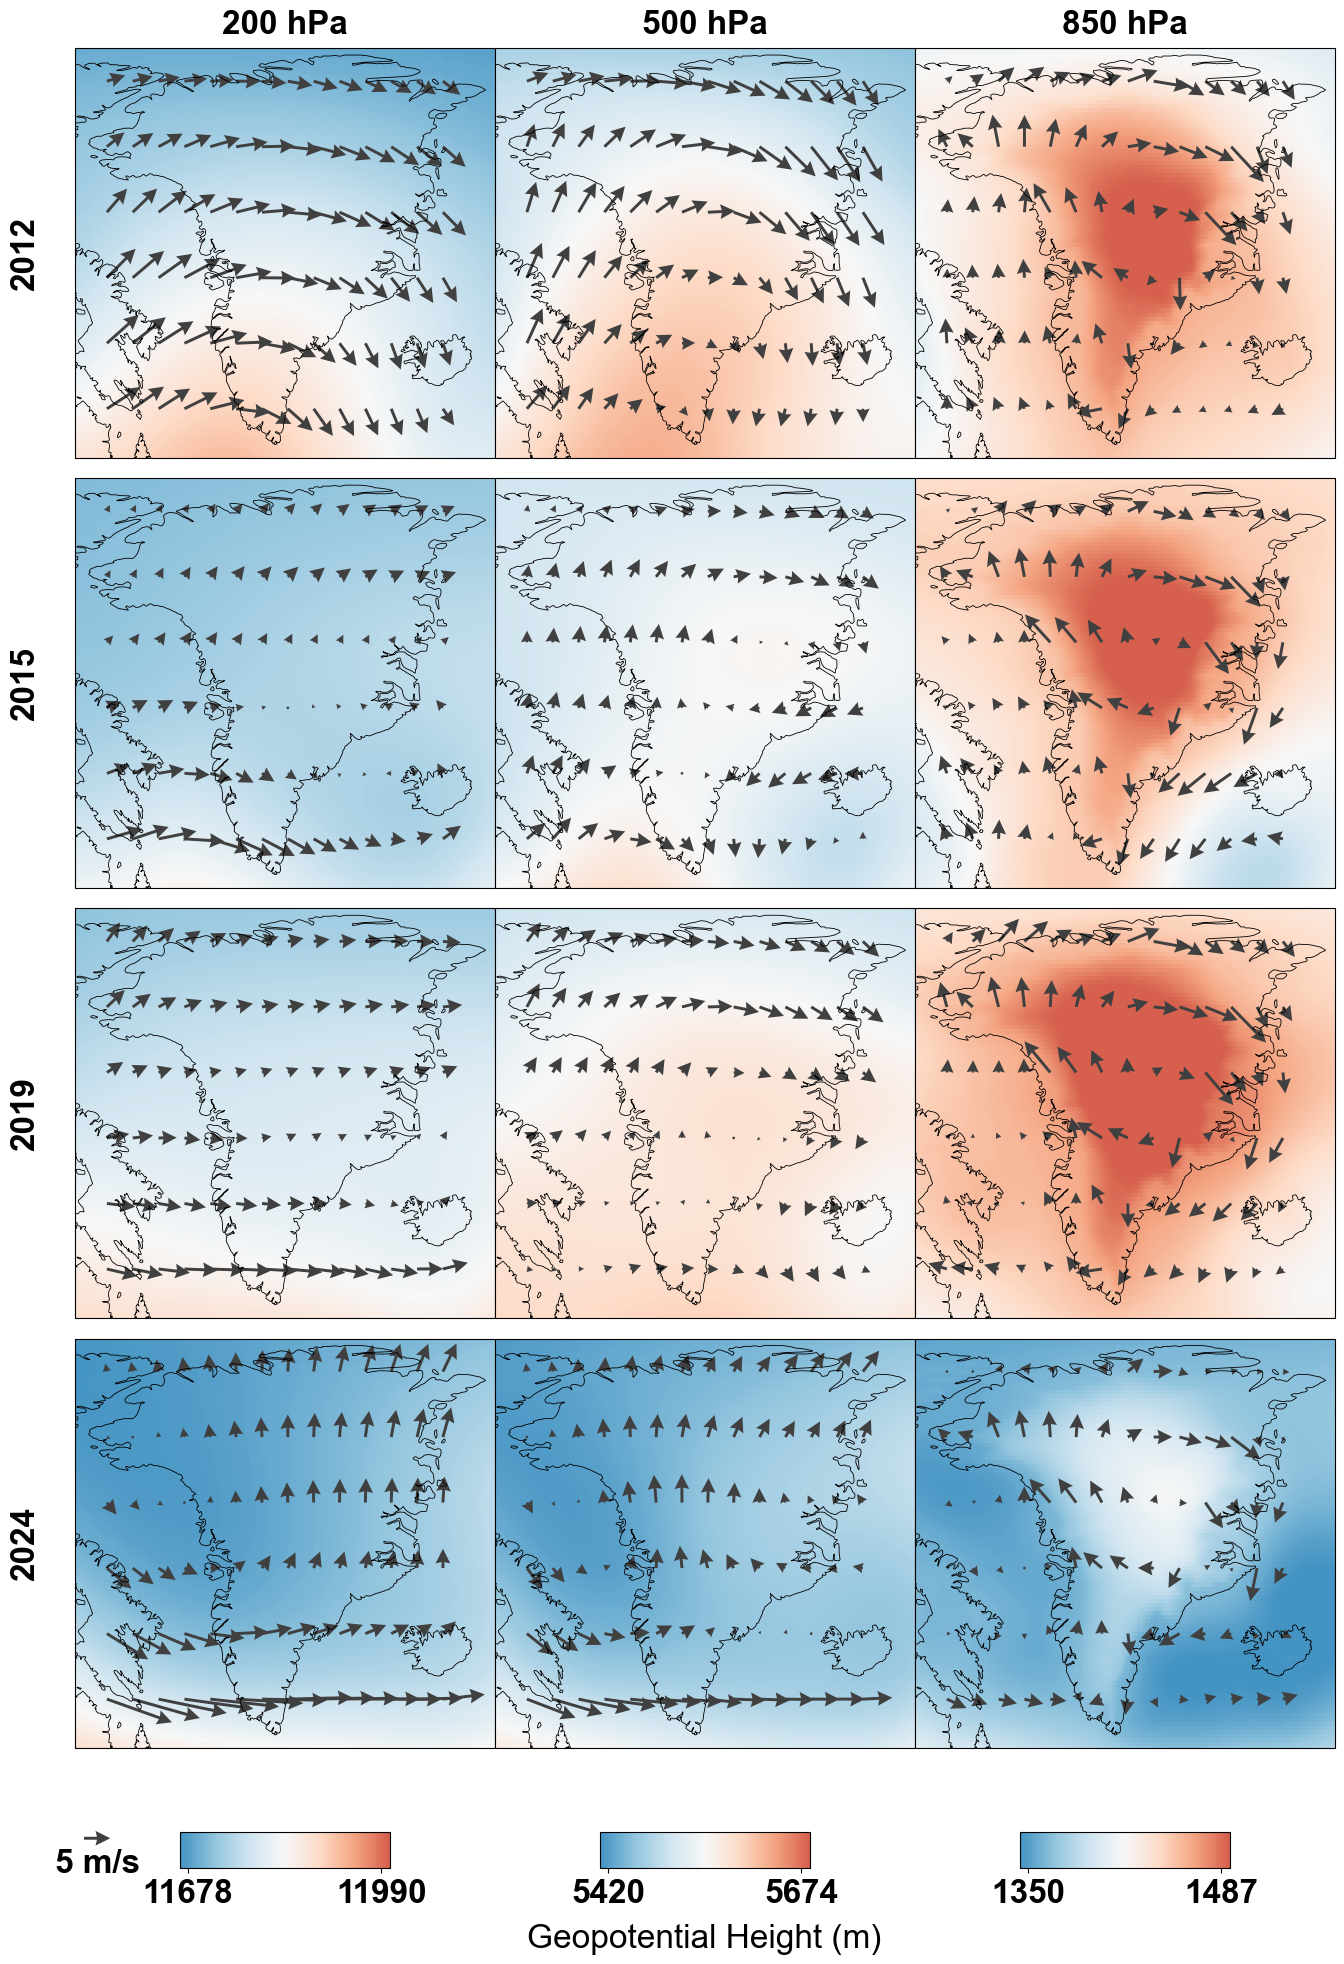

In [31]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors  # 【新增】用于处理颜色
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ===================== 辅助函数：截断色标 =====================
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    """
    截取色标的一部分，使颜色更淡（去掉两端深色）。
    minval, maxval: 0.0-1.0 之间，0.5 是中间白色。
    例如取 0.2-0.8 可以去掉最深的红和蓝。
    """
    new_cmap = mcolors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

# ===================== 参数 =====================
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"

# 1. 修改年份
YEARS = [2012, 2015, 2019, 2024]
LEVELS = [200, 500, 850]

LON_MIN, LON_MAX = -75, -10
LAT_MIN, LAT_MAX = 59, 83

# 箭头内缩
MARGIN_LON = 5
MARGIN_LAT = 3

arrow_lon_min = LON_MIN + MARGIN_LON
arrow_lon_max = LON_MAX - MARGIN_LON
arrow_lat_min = LAT_MIN + MARGIN_LAT
arrow_lat_max = LAT_MAX 

# 格陵兰区域
GREENLAND_LON_MIN, GREENLAND_LON_MAX = -73, -15
GREENLAND_LAT_MIN, GREENLAND_LAT_MAX = 60, 82

plt.rcParams["font.size"] = 24
plt.rcParams["font.weight"] = "bold"

# ===================== 数据读取 =====================
ds = xr.open_dataset(path)
ds["z"] = ds["z"] / 9.80665

# ========== 加速点 1：提前计算所有 YEAR × LEVEL 平均 ==========
mean_cache = {}

for year in YEARS:
    idx = (ds.valid_time.dt.year == year) & ds.valid_time.dt.month.isin([6, 7, 8])
    ds_year = ds.isel(valid_time=idx).mean("valid_time") 

    for lev in LEVELS:
        mean_cache[(year, lev)] = ds_year.sel(pressure_level=lev)

# ========== 提前计算色标范围 ==========
z_vminmax = {}
for lev in LEVELS:
    all_vals = [mean_cache[(y, lev)].z.values for y in YEARS]
    arr = np.concatenate([x.flatten() for x in all_vals])
    z_vminmax[lev] = (np.percentile(arr, 2), np.percentile(arr, 98))

# ===================== 【修改点】创建淡色色标 =====================
# RdBu_r 原始范围：0.0(深蓝) -> 0.5(白) -> 1.0(深红)
# 修改为：0.2(浅蓝) -> 0.8(浅红)
# 如果觉得还不够淡，可以改为 0.25 -> 0.75
base_cmap = plt.get_cmap("RdBu_r")
pale_cmap = truncate_colormap(base_cmap, 0.2, 0.8)

# ===================== 画布 =====================
fig = plt.figure(figsize=(15, 20))
gs = fig.add_gridspec(
    nrows=len(YEARS), ncols=len(LEVELS),
    left=0.03, right=0.87,
    top=0.97, bottom=0.12,
    wspace=0.0, hspace=0.05
)

col_mappable = {}
axes_list = []
last_quiver = None 

# ===================== 正式绘图 =====================
for r, year in enumerate(YEARS):
    for c, lev in enumerate(LEVELS):

        ax = fig.add_subplot(gs[r, c], projection=ccrs.PlateCarree())
        if r == 0 and c == 0:
            axes_list.append(ax)

        ax.set_extent([LON_MIN, LON_MAX, LAT_MIN, LAT_MAX])
        ax.set_aspect("auto")

        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
        ax.add_feature(cfeature.LAND, facecolor="none", linewidth=0.4)
        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

        d = mean_cache[(year, lev)]
        lon, lat = d.longitude, d.latitude
        z = d.z
        u, v = d.u, d.v

        # 背景色
        vmin, vmax = z_vminmax[lev]
        
        # 【修改点】这里使用 pale_cmap
        p = ax.pcolormesh(
            lon, lat, z,
            cmap=pale_cmap,    # 使用自定义的淡色色标
            shading="nearest",
            vmin=vmin, vmax=vmax,
            rasterized=True
        )
        if r == 0:
            col_mappable[c] = p

        # ========== 箭头绘制 ==========
        step = 16 
        lon2d, lat2d = np.meshgrid(lon.values[::step], lat.values[::step])
        u2d = u.values[::step, ::step]
        v2d = v.values[::step, ::step]

        mask = (
            (GREENLAND_LON_MIN <= lon2d) & (lon2d <= GREENLAND_LON_MAX) &
            (GREENLAND_LAT_MIN <= lat2d) & (lat2d <= GREENLAND_LAT_MAX) &
            (arrow_lon_min <= lon2d) & (lon2d <= arrow_lon_max) &
            (arrow_lat_min <= lat2d) & (lat2d <= arrow_lat_max)
        )

        last_quiver = ax.quiver(
            lon2d[mask], lat2d[mask],
            u2d[mask], v2d[mask],
            color='#404040', scale=80,
            width=0.007, headwidth=5, headlength=5
        )

        # 列标题
        if r == 0:
            ax.text(0.5, 1.02, f"{lev} hPa",
                    transform=ax.transAxes, ha="center", va="bottom")

        # 行标题
        if c == 0:
            ax.text(-0.08, 0.5, f"{year}",
                    transform=ax.transAxes,
                    ha="right", va="center",
                    rotation=90)

# ===================== 色标自动对齐每列 =====================
cb_y_pos = 0.06
cb_height = 0.018

for c, lev in enumerate(LEVELS):
    m = col_mappable.get(c)
    if m is None:
        continue

    bbox = gs[:, c].get_position(fig)
    x0, x1 = bbox.x0, bbox.x1

    col_center = (x0 + x1) / 2
    new_width = (x1 - x0) * 0.50       
    new_x0 = col_center - new_width / 2 

    cax = fig.add_axes([new_x0, cb_y_pos, new_width, cb_height])

    cb = plt.colorbar(m, cax=cax, orientation="horizontal")

    vmin, vmax = z_vminmax[lev]
    offset = (vmax - vmin) * 0.04
    cb.set_ticks([vmin + offset, vmax - offset])
    cb.set_ticklabels([f"{vmin:.0f}", f"{vmax:.0f}"])
    cb.ax.tick_params(labelsize=24)

    if c == 1:
        cb.set_label("Geopotential Height (m)", labelpad=10)

# ===================== 左下角水平 5 m/s 箭头 =====================
if last_quiver is not None:
    plt.quiverkey(
        last_quiver,           
        X=0.045, Y=0.075,      
        U=5,                   
        label='5 m/s',         
        labelpos='S',          
        coordinates='figure',  
        fontproperties={'weight': 'bold', 'size': 24}
    )

plt.show()

In [6]:
import xarray as xr

# 请确保路径正确
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc"

try:
    ds = xr.open_dataset(path)
    print("===== 1. 维度信息 (Dimensions) =====")
    print(ds.dims)
    
    print("\n===== 2. 坐标信息 (Coordinates) =====")
    print(ds.coords)
    
    print("\n===== 3. 变量信息 (Variables) =====")
    print(ds.data_vars)
    
    print("\n===== 4. 坐标属性 (Attributes) =====")
    # 检查经度范围和纬度方向
    print(f"Longitude range: {ds.longitude.min().values} to {ds.longitude.max().values}")
    print(f"Latitude range: {ds.latitude.min().values} to {ds.latitude.max().values}")
    print(f"Latitude first 3 values: {ds.latitude.values[:3]}") # 检查升降序
    
    # 检查时间步长
    print(f"\nTime range: {ds.valid_time.min().values} to {ds.valid_time.max().values}")

except Exception as e:
    print(f"读取文件出错: {e}")

===== 1. 维度信息 (Dimensions) =====
FrozenMappingWarningOnValuesAccess({'valid_time': 910, 'pressure_level': 3, 'latitude': 141, 'longitude': 721})

===== 2. 坐标信息 (Coordinates) =====
Coordinates:
    number          int64 8B ...
  * valid_time      (valid_time) datetime64[ns] 7kB 1950-01-01 ... 2025-10-01
  * pressure_level  (pressure_level) float64 24B 850.0 500.0 200.0
  * latitude        (latitude) float64 1kB 90.0 89.75 89.5 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 6kB -130.0 -129.8 -129.5 ... 49.75 50.0
    expver          (valid_time) <U4 15kB ...

===== 3. 变量信息 (Variables) =====
Data variables:
    z        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    u        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    v        (valid_time, pressure_level, latitude, longitude) float32 1GB ...
    w        (valid_time, pressure_level, latitude, longitude) float32 1GB ...

===== 4. 坐标属性 (Attributes) =====
Longitude range: -130.0 t

C:\Users\11823\AppData\Local\Temp\ipykernel_113868\2813931304.py:11: UserWarning: The specified chunks separate the stored chunks along dimension "valid_time" starting at index 100. This could degrade performance. Instead, consider rechunking after loading.
  ds = xr.open_dataset(path, chunks={'valid_time': 100})


正在提取 JJA 数据...


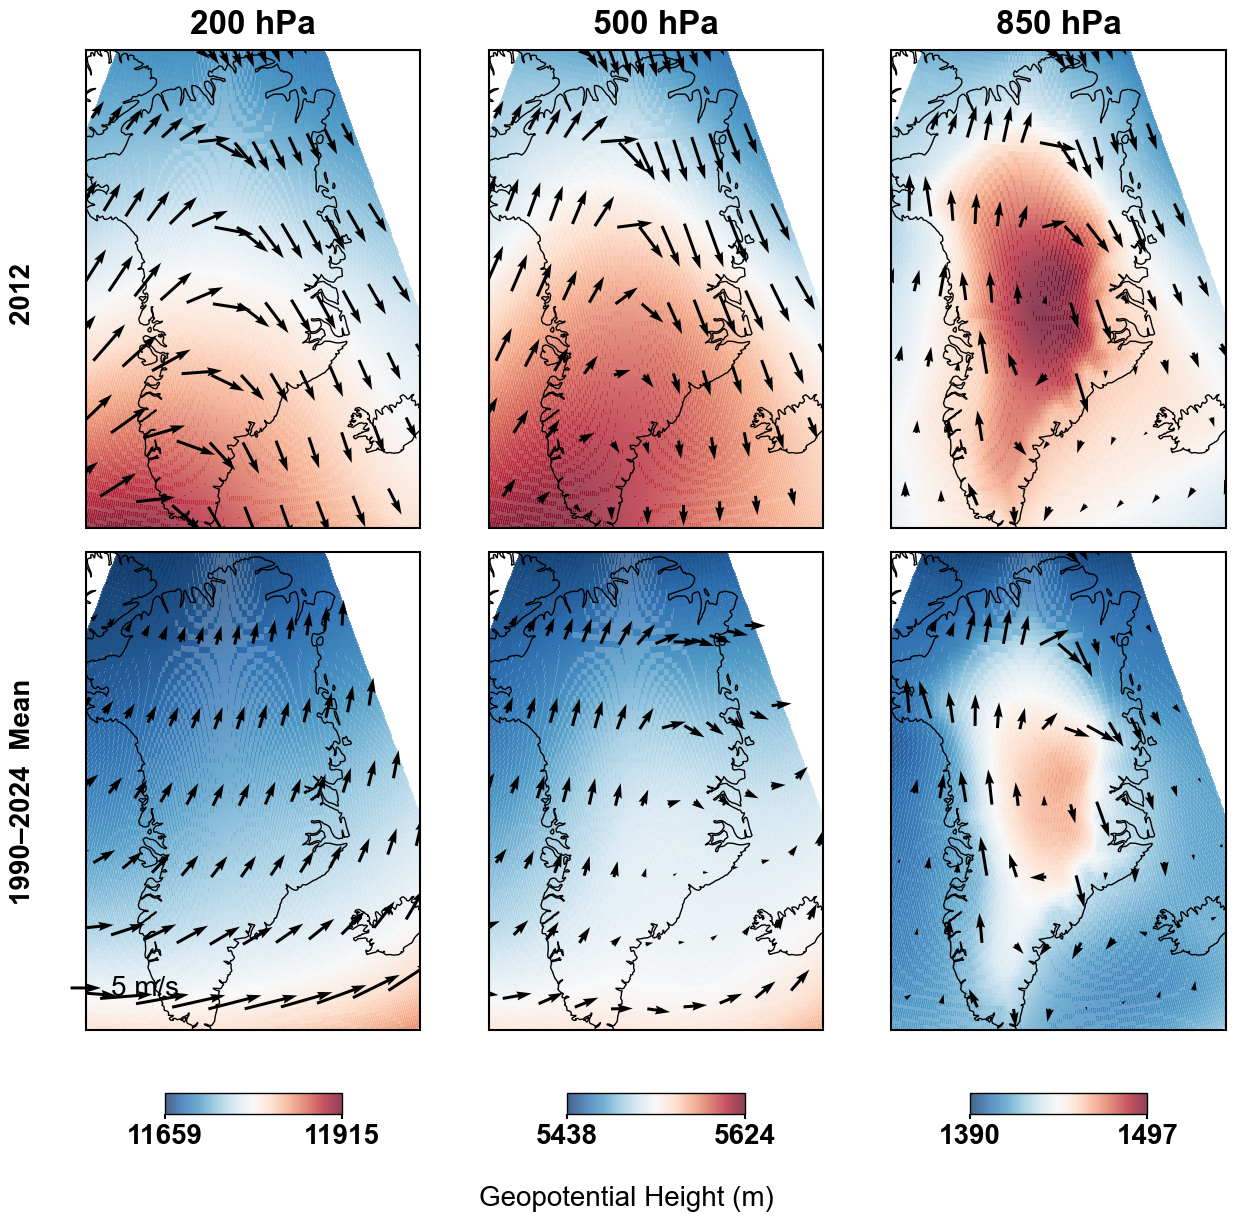

In [20]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import sys

# ===================== 1. 数据加载与 JJA 严格筛选 =====================
def load_and_preprocess(path, levels):
    try:
        ds = xr.open_dataset(path, chunks={'valid_time': 100})
        if 'lat' in ds.coords: ds = ds.rename({'lat': 'latitude', 'lon': 'longitude'})
        
        # 自动识别纬度降序 (90 -> 55)
        is_descending = ds.latitude[0] > ds.latitude[-1]
        lat_slice = slice(84, 59) if is_descending else slice(59, 84)
        
        # 裁剪空间并转换单位
        ds_sub = ds[['z', 'u', 'v']].sel(
            pressure_level=levels, longitude=slice(-75, -10), latitude=lat_slice
        ).compute()
        ds_sub["z"] = ds_sub["z"] / 9.80665
        
        # 【严格确认】只提取 6, 7, 8 月的数据
        print("正在提取 JJA 数据...")
        # 行 1: 2012 仅夏季
        d_2012 = ds_sub.sel(valid_time=slice("2012-06-01", "2012-08-31")).mean("valid_time")
        
        # 行 2: 长期气候态 (1990-2024) 仅夏季
        clim_range = ds_sub.sel(valid_time=slice("1990-01-01", "2024-12-31"))
        d_clim = clim_range.sel(valid_time=clim_range.valid_time.dt.month.isin([6, 7, 8])).mean("valid_time")
        
        return d_2012, d_clim
    except Exception as e:
        print(f"数据初始化失败: {e}")
        sys.exit(1)

# ===================== 2. 样式配置 (Arial 20pt) =====================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 20,
    "axes.labelweight": "bold", 
    "axes.titleweight": "bold"
})

LEVELS = [200, 500, 850]
res_2012, res_clim = load_and_preprocess(r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\200500850UVZ.nc", LEVELS)

# 投影：兰伯特投影
map_proj = ccrs.LambertConformal(central_longitude=-41.5, central_latitude=71)
data_proj = ccrs.PlateCarree()

# ===================== 3. 绘图渲染 (紧凑布局优化) =====================
# 调窄 figsize 宽度，强制缩小列间距
fig = plt.figure(figsize=(15, 14))
# wspace 和 hspace 设为极小，消除自适应空隙
gs = fig.add_gridspec(2, 3, wspace=0.02, hspace=0.05, left=0.12, right=0.92, top=0.92, bottom=0.22)

rows = [("2012 ", res_2012), ("1990–2024  Mean", res_clim)]
col_mappables = [None] * 3
last_q = None

for r, (row_label, r_ds) in enumerate(rows):
    for c, lev in enumerate(LEVELS):
        ax = fig.add_subplot(gs[r, c], projection=map_proj)
        ax.set_extent([-58, -18, 59.5, 83.5], crs=data_proj)
        
        data = r_ds.sel(pressure_level=lev)
        v1, v2 = res_2012.sel(pressure_level=lev).z.values, res_clim.sel(pressure_level=lev).z.values
        vmin, vmax = np.nanmin([v1, v2]), np.nanmax([v1, v2])

        # A. 背景：红白蓝渐变
        im = ax.pcolormesh(data.longitude, data.latitude, data.z,
                           transform=data_proj, cmap='RdBu_r', 
                           vmin=vmin, vmax=vmax, shading='auto', rasterized=True, alpha=0.75)
        if r == 0: col_mappables[c] = (im, vmin, vmax)

        # B. ========================箭头
        q_ds = data.isel(latitude=slice(None,None,15), longitude=slice(None,None,18))
        last_q = ax.quiver(q_ds.longitude.values, q_ds.latitude.values, 
                           q_ds.u.values, q_ds.v.values,
                           transform=data_proj, color='black', 
                           scale=55, width=0.009, headwidth=3, zorder=5)

        ax.add_feature(cfeature.COASTLINE, linewidth=1, edgecolor='black')
        
        # C. 标题与标注 (行标题与列标题全部加粗)
        if r == 0:
            ax.set_title(f"{int(lev)} hPa", pad=12, weight='bold') 
        if c == 0:
            ax.text(-0.15, 0.5, row_label, transform=ax.transAxes, 
                    rotation=90, va='center', ha='right', weight='bold') 

# ===================== 4. 底部定制：色标与图例 =====================

# 1. 每一列下方放置半宽色标 (45% 子图宽度)
for i, (m, v_min, v_max) in enumerate(col_mappables):
    pos = gs[1, i].get_position(fig)
    cax_w = pos.width * 0.45 
    cax_x = pos.x0 + (pos.width - cax_w) / 2 
    cax = fig.add_axes([cax_x, 0.16, cax_w, 0.015])
    
    cb = plt.colorbar(m, cax=cax, orientation='horizontal')
    cb.set_ticks([v_min, v_max])
    cb.ax.set_xticklabels([f"{v_min:.0f}", f"{v_max:.0f}"])
    cb.outline.set_linewidth(1)

# 2. 全局单位标签
fig.text(0.5, 0.1, "Geopotential Height (m)", ha='center', va='center', fontsize=20, weight='normal')

# 3. 风场图例 (5 m/s)：右移至画布右侧 85% 位置
if last_q:
    plt.quiverkey(last_q, 0.15, 0.25, 5, "5 m/s", labelpos='E', 
                  coordinates='figure', fontproperties={'family': 'Arial', 'size': 20, 'weight': 'normal'})

plt.show()

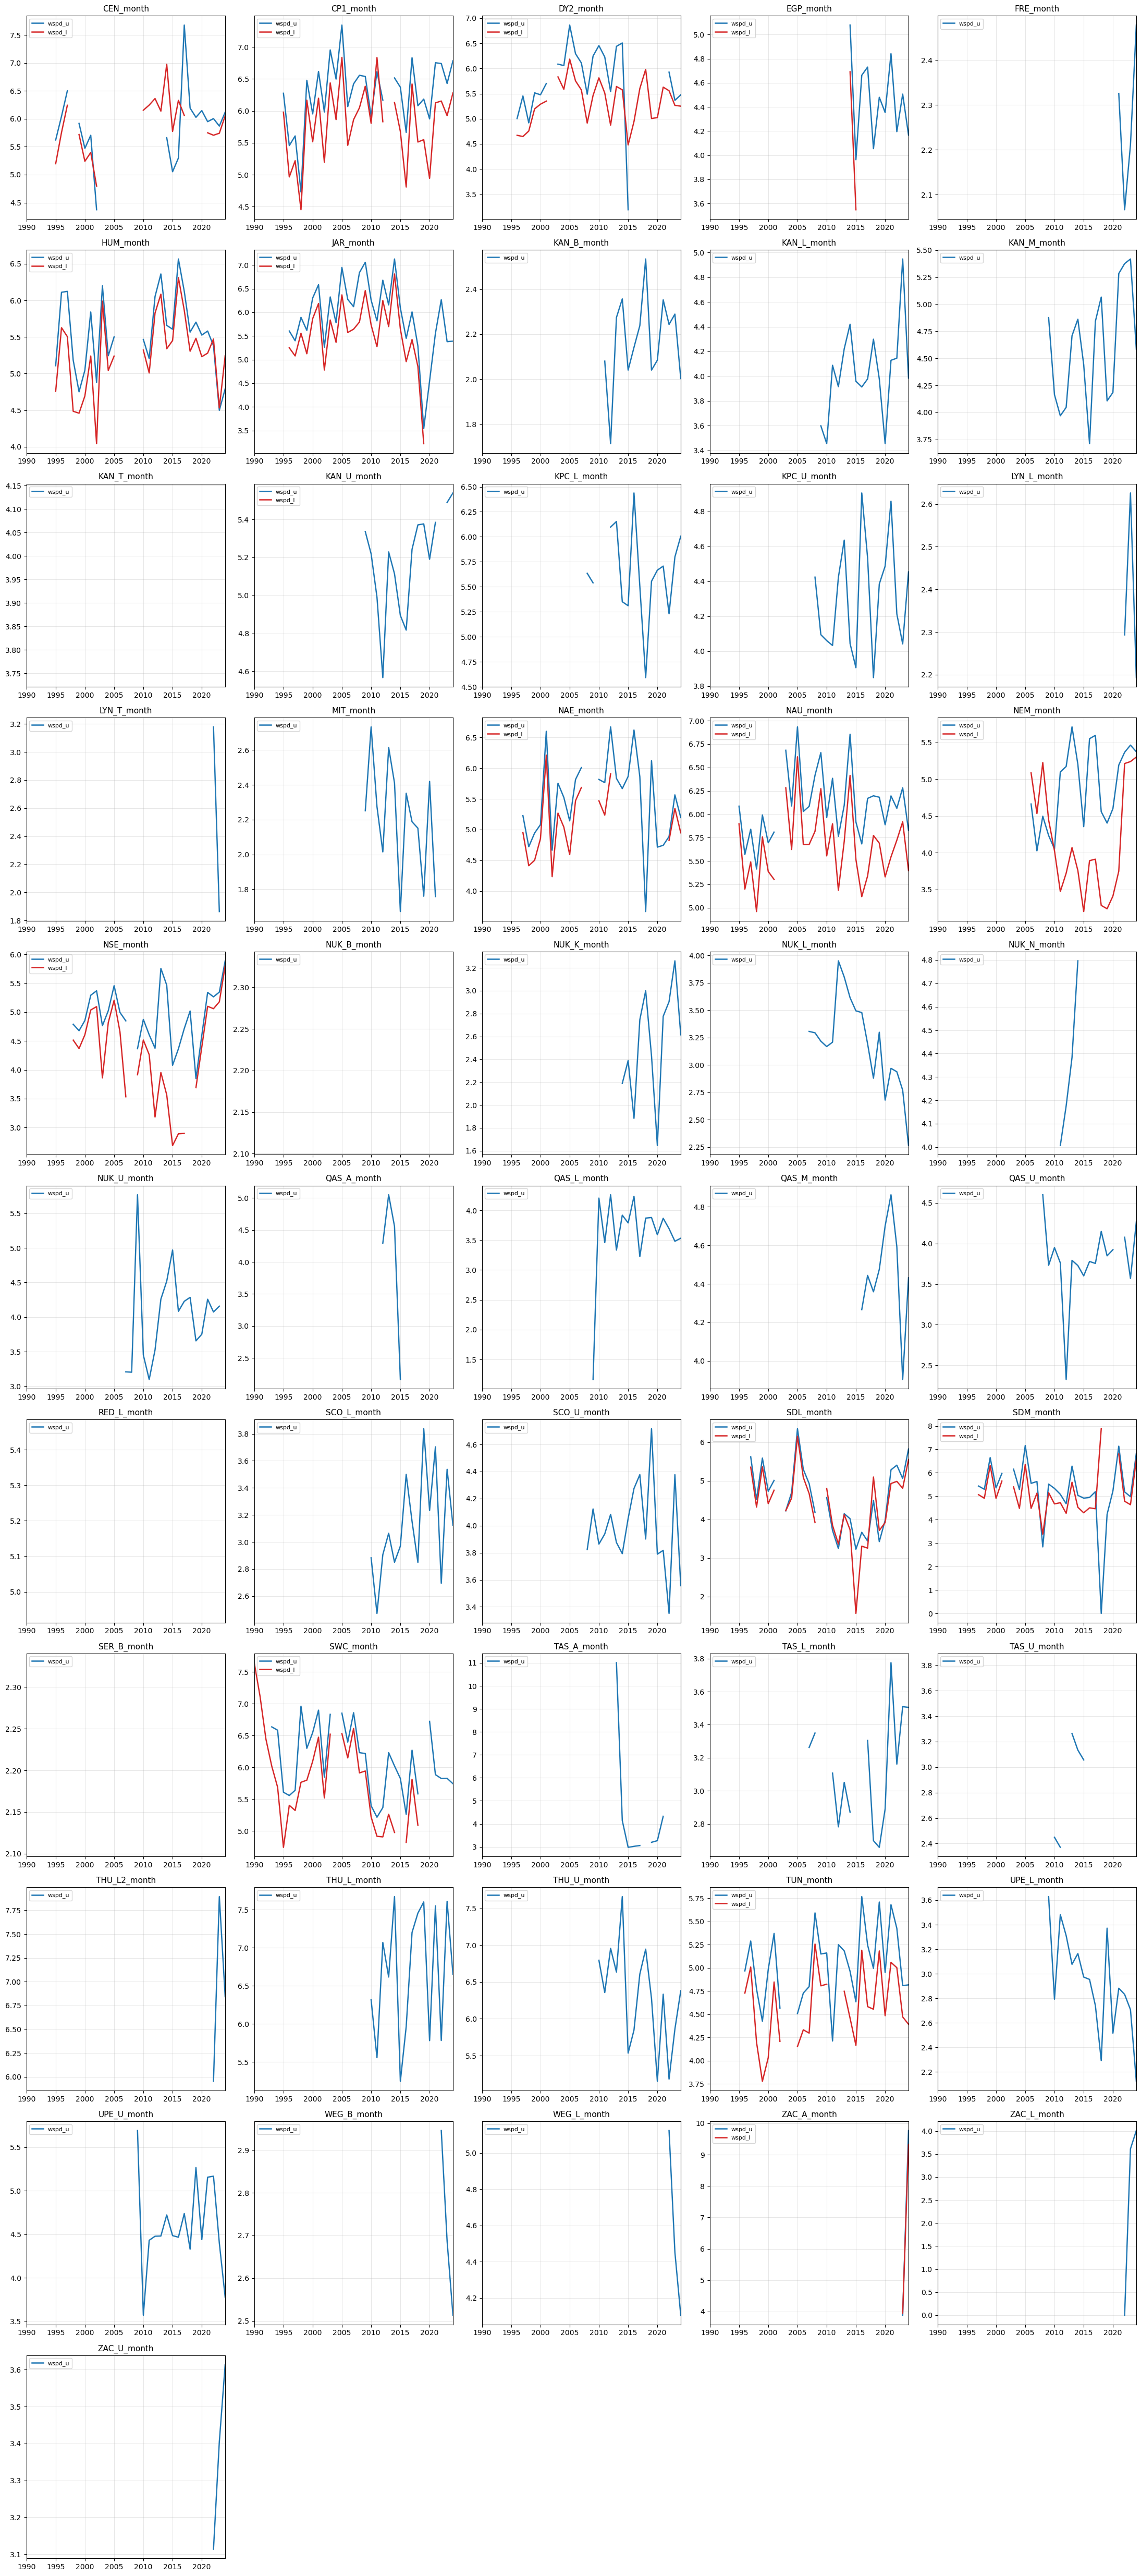

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ===================== 参数 =====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\month"

START_YEAR = 1990
END_YEAR   = 2024

COLORS = {
    "wspd_u": "tab:blue",
    "wspd_l": "tab:red"
}

# ===================== 扫描所有站点文件 =====================
files = [f for f in os.listdir(BASE_DIR) if f.endswith(".csv") and "month" in f.lower()]
files = sorted(files)  # 排序，结果一致


# ===================== 计算行列数 =====================
n = len(files)
cols = 5
rows = (n // cols) + (1 if n % cols != 0 else 0)

fig, axes = plt.subplots(rows, cols, figsize=(22, 4.5 * rows), sharex=False)
axes = axes.flatten()

# ===================== 主循环：每个站点一个小图 =====================
for idx, file in enumerate(files):
    ax = axes[idx]
    station = file.replace(".csv", "")

    path = os.path.join(BASE_DIR, file)
    df = pd.read_csv(path)

    # 检查是否有时间列
    if "time" not in df.columns:
        ax.set_title(station + " (no time column)")
        continue

    # 时间解析
    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"])

    # 限定年份
    df = df[(df["time"].dt.year >= START_YEAR) & (df["time"].dt.year <= END_YEAR)]
    if df.empty:
        ax.set_title(station + " (no data 1990-2024)")
        continue

    # 聚合JJA
    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month
    df_jja = df[df["month"].isin([6, 7, 8])]

    # 空图情况
    if df_jja.empty:
        ax.set_title(station + " (no JJA data)")
        continue

    yearly = {}

    # wspd_u
    if "wspd_u" in df_jja.columns:
        yearly["wspd_u"] = df_jja.groupby("year")["wspd_u"].mean()

    # wspd_l
    if "wspd_l" in df_jja.columns:
        yearly["wspd_l"] = df_jja.groupby("year")["wspd_l"].mean()

    # 如果2个都没有 → 跳过
    if len(yearly) == 0:
        ax.set_title(station + " (no wspd vars)")
        continue

    # ---- 画图 ----
    for var, series in yearly.items():
        ax.plot(series.index, series.values, label=var, color=COLORS[var], linewidth=1.8)

    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_title(station, fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(np.arange(1990, 2025, 5))

    ax.legend(fontsize=8, loc="upper left")

# ===================== 去掉多余子图 =====================
for j in range(len(files), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


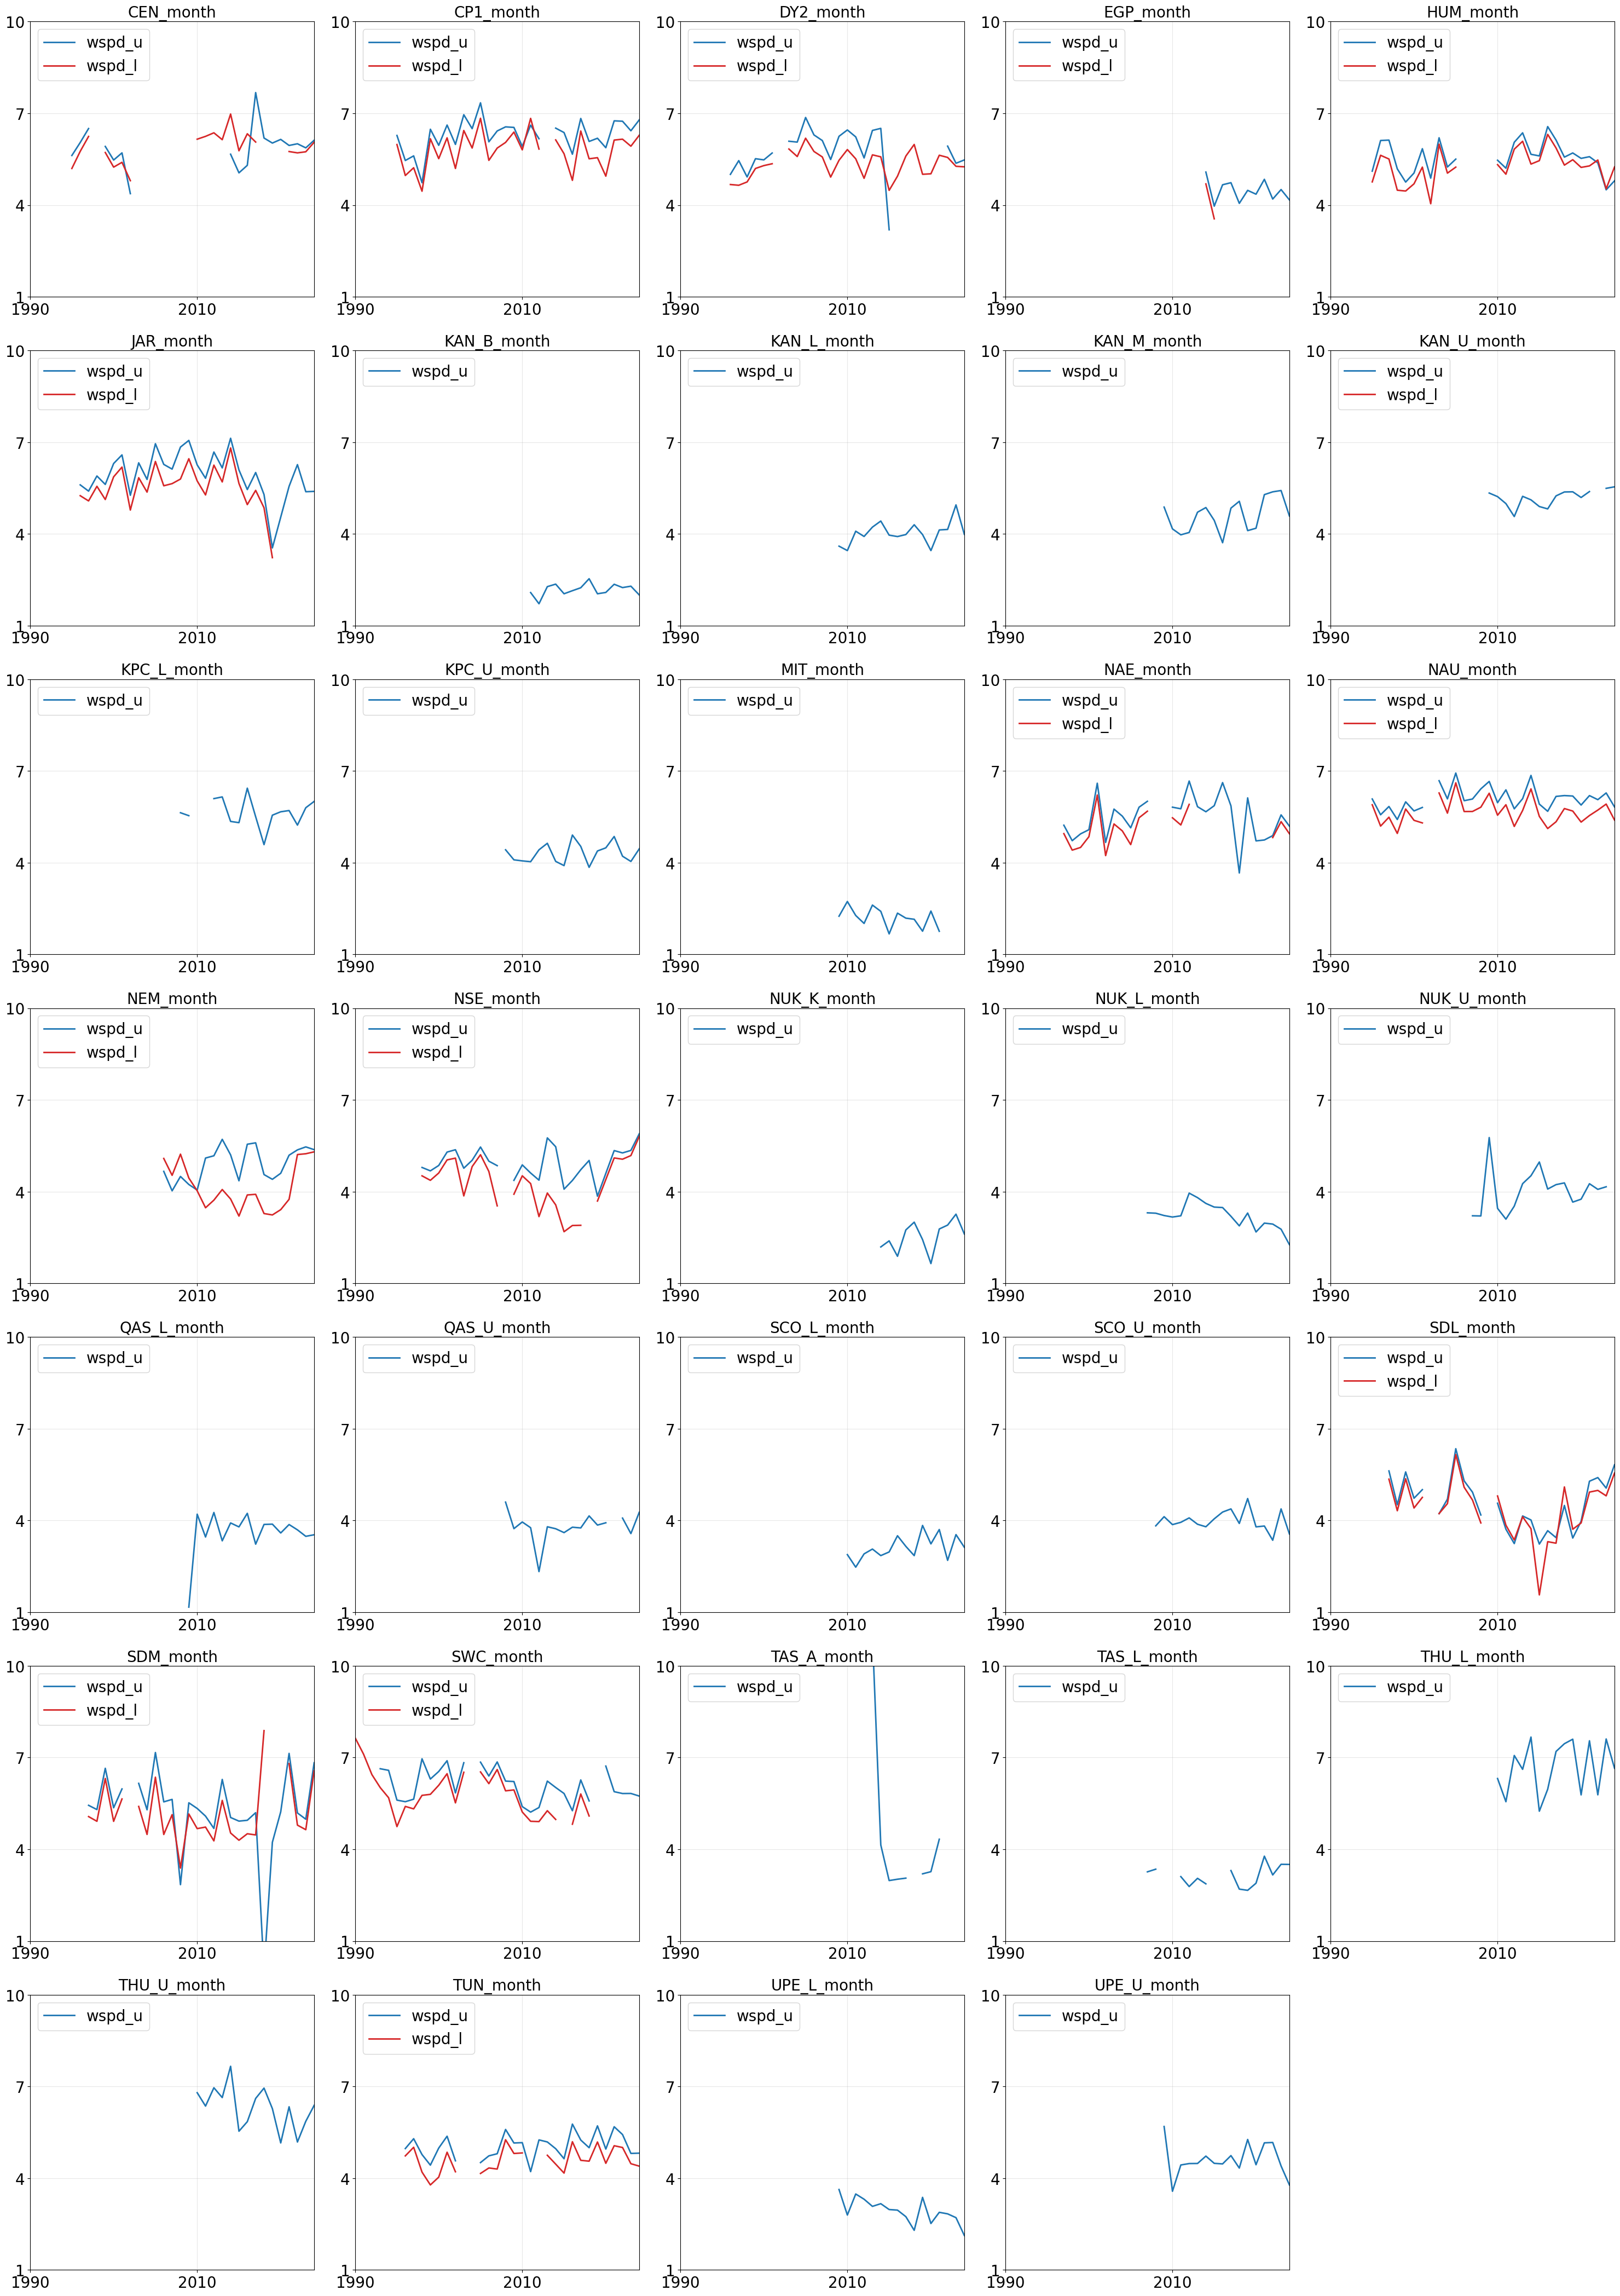


⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：
 ➤ TAS_A_month



In [11]:
# -*- coding: utf-8 -*-
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# ===================== 参数 =====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\dataverse_files\month"

START_YEAR = 1990
END_YEAR   = 2024

TREND_THRESHOLD = 0.1  # 斜率变化阈值 (m/s 每年)

# 全局大字号
plt.rcParams["font.size"] = 20
plt.rcParams["axes.titlesize"] = 20
plt.rcParams["axes.labelsize"] = 20
plt.rcParams["xtick.labelsize"] = 20
plt.rcParams["ytick.labelsize"] = 20
plt.rcParams["legend.fontsize"] = 20

COLORS = {"wspd_u": "tab:blue", "wspd_l": "tab:red"}

# ===================== 扫描文件 =====================
files = [f for f in os.listdir(BASE_DIR) if f.endswith(".csv") and "month" in f.lower()]
files = sorted(files)

# ===================== 画布布局 =====================
n = len(files)
cols = 5
rows = (n // cols) + (1 if n % cols else 0)

fig, axes = plt.subplots(rows, cols, figsize=(30, 6 * rows))
axes = axes.flatten()

trend_stations = []  # 存储趋势明显的站点名称
plot_idx = 0

# ===================== 趋势函数 =====================
def calc_trend(series):
    """对单站点单变量 series 做线性趋势，自动 dropna()，出错返回 None"""
    s = series.dropna()
    if len(s) < 5:  # 少于 5 年不计算趋势
        return None
    
    x = np.array(s.index).reshape(-1, 1)
    y = s.values.reshape(-1, 1)
    
    try:
        model = LinearRegression().fit(x, y)
        return model.coef_[0][0]  # slope (m/s per year)
    except:
        return None

# ===================== 主循环 =====================
for file in files:
    path = os.path.join(BASE_DIR, file)
    df = pd.read_csv(path)
    station = file.replace(".csv", "")

    # 时间列检查
    if "time" not in df.columns:
        continue

    df["time"] = pd.to_datetime(df["time"], errors="coerce")
    df = df.dropna(subset=["time"])

    df = df[(df["time"].dt.year >= START_YEAR) & (df["time"].dt.year <= END_YEAR)]
    if df.empty:
        continue

    df["year"] = df["time"].dt.year
    df["month"] = df["time"].dt.month

    # 只取 JJA
    df_jja = df[df["month"].isin([6, 7, 8])]
    if df_jja.empty:
        continue

    # 聚合年均
    series_u = df_jja.groupby("year")["wspd_u"].mean() if "wspd_u" in df_jja.columns else None
    series_l = df_jja.groupby("year")["wspd_l"].mean() if "wspd_l" in df_jja.columns else None

    # wspd_u/l 都没有 → 跳过
    if (series_u is None) and (series_l is None):
        continue

    # 有效年份过滤（≥10 年）
    valid_years = set()
    if series_u is not None: valid_years |= set(series_u.index)
    if series_l is not None: valid_years |= set(series_l.index)

    if len(valid_years) < 10:
        continue

    # ===================== 趋势计算 =====================
    slope = None

    if series_u is not None:
        slope = calc_trend(series_u)

    if slope is None and series_l is not None:
        slope = calc_trend(series_l)

    trend_flag = False
    if slope is not None and abs(slope) >= TREND_THRESHOLD:
        trend_flag = True
        trend_stations.append(station)

    # ===================== 开始画图 =====================
    ax = axes[plot_idx]

    if series_u is not None:
        ax.plot(series_u.index, series_u.values, label="wspd_u",
                color=COLORS["wspd_u"], linewidth=2)

    if series_l is not None:
        ax.plot(series_l.index, series_l.values, label="wspd_l",
                color=COLORS["wspd_l"], linewidth=2)

    ax.set_title(station)
    ax.grid(alpha=0.3)

    # ---- x 轴 ----
    ax.set_xticks([1990, 2010])
    ax.set_xlim(1990, 2024)

    # ---- y 轴统一 ----
    ax.set_ylim(1, 10)
    ax.set_yticks([1, 4, 7, 10])

    ax.legend(loc="upper left")

    plot_idx += 1

# ==== 删除多余空子图 ====
for j in range(plot_idx, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# ===================== 输出明显趋势站点 =====================
print("\n==============================")
print("⚠️ 有明显变化趋势的站点（|斜率| ≥ 0.02 m/s/yr）：")
for s in trend_stations:
    print(" ➤", s)
print("==============================\n")
